In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv('dataset/laptopData.csv')

In [3]:
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1273 non-null   float64
 1   Company           1273 non-null   object 
 2   TypeName          1273 non-null   object 
 3   Inches            1273 non-null   object 
 4   ScreenResolution  1273 non-null   object 
 5   Cpu               1273 non-null   object 
 6   Ram               1273 non-null   object 
 7   Memory            1273 non-null   object 
 8   Gpu               1273 non-null   object 
 9   OpSys             1273 non-null   object 
 10  Weight            1273 non-null   object 
 11  Price             1273 non-null   float64
dtypes: float64(2), object(10)
memory usage: 122.3+ KB


In [5]:
df.shape

(1303, 12)

In [6]:
df.describe()

,Unnamed: 0,Price
count,1273.000000,1273.000000
mean,652.674784,59955.814073
std,376.493027,37332.251005
min,0.000000,9270.720000
25%,327.000000,31914.720000
50%,652.000000,52161.120000
75%,980.000000,79333.387200
max,1302.000000,324954.720000


In [7]:
df.columns

Index(['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution',
       'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='object')

In [8]:
df.isnull().sum()

Unnamed: 0          30
Company             30
TypeName            30
Inches              30
ScreenResolution    30
Cpu                 30
Ram                 30
Memory              30
Gpu                 30
OpSys               30
Weight              30
Price               30
dtype: int64

In [9]:
df = df.dropna(how='all').copy()

In [10]:
df = df.drop(columns=['Unnamed: 0'])

In [11]:
df.duplicated().sum()

np.int64(29)

In [12]:
df = df.drop_duplicates().copy()

In [13]:
df.isnull().sum()

Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

In [14]:
df['Inches'] = df['Inches'].replace('?', np.nan).astype(float)
df['Weight'] = df['Weight'].str.replace('kg', '').replace('?', np.nan).astype(float)
df['Ram'] = df['Ram'].str.replace('GB', '').astype(int)

In [15]:
impute = SimpleImputer(strategy='median')

df[['Inches', 'Weight']] = impute.fit_transform(df[['Inches', 'Weight']])

In [16]:
df['Touchscreen'] = df['ScreenResolution'].str.contains('Touchscreen').astype(int)
df['IPS'] = df['ScreenResolution'].str.contains('IPS').astype(int)
res = df['ScreenResolution'].str.extract(r'(\d+)x(\d+)').astype(int)
df['X_res'] = res[0]
df['Y_res'] = res[1]
df['PPI'] = (((df['X_res'] ** 2 + df['Y_res'] ** 2) ** 0.5) / df['Inches']).round(2)
df = df.drop(columns=['ScreenResolution', 'X_res', 'Y_res'])

In [17]:
df['Cpu_Speed'] = df['Cpu'].str.extract(r'(\d+\.?\d*)GHz').astype(float)

def cpu_brand(text):
    if text.startswith('Intel Core i'):
        return ' '.join(text.split()[:3])
    if text.startswith('Intel'):
        return 'Other Intel'
    return 'AMD'

df['Cpu_Brand'] = df['Cpu'].apply(cpu_brand)
df = df.drop(columns=['Cpu'])

In [18]:
def storage_gb(text, kind):
    total = 0
    for part in text.split('+'):
        part = part.strip()
        if kind in part:
            size = part.split(kind)[0].strip()
            if 'TB' in size:
                total += float(size.replace('TB', '')) * 1000
            else:
                total += float(size.replace('GB', ''))
    return total

df['Memory'] = df['Memory'].replace('?', '0GB Other')
df['SSD'] = df['Memory'].apply(lambda x: storage_gb(x, 'SSD'))
df['HDD'] = df['Memory'].apply(lambda x: storage_gb(x, 'HDD'))
df['Flash'] = df['Memory'].apply(lambda x: storage_gb(x, 'Flash Storage'))
df['Hybrid'] = df['Memory'].apply(lambda x: storage_gb(x, 'Hybrid'))
df = df.drop(columns=['Memory'])

In [19]:
df['Gpu_Brand'] = df['Gpu'].str.split().str[0]
df = df.drop(columns=['Gpu'])

In [20]:
df['OpSys'] = df['OpSys'].replace({
    'Windows 10': 'Windows', 'Windows 7': 'Windows', 'Windows 10 S': 'Windows',
    'macOS': 'Mac', 'Mac OS X': 'Mac'
})
df['OpSys'] = df['OpSys'].replace({'No OS': 'Other', 'Android': 'Other', 'Chrome OS': 'Other'})

In [21]:
df.isnull().sum()

Company        0
TypeName       0
Inches         0
Ram            0
OpSys          0
Weight         0
Price          0
Touchscreen    0
IPS            0
PPI            0
Cpu_Speed      0
Cpu_Brand      0
SSD            0
HDD            0
Flash          0
Hybrid         0
Gpu_Brand      0
dtype: int64

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1244 entries, 0 to 1273
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Company      1244 non-null   object 
 1   TypeName     1244 non-null   object 
 2   Inches       1244 non-null   float64
 3   Ram          1244 non-null   int64  
 4   OpSys        1244 non-null   object 
 5   Weight       1244 non-null   float64
 6   Price        1244 non-null   float64
 7   Touchscreen  1244 non-null   int64  
 8   IPS          1244 non-null   int64  
 9   PPI          1244 non-null   float64
 10  Cpu_Speed    1244 non-null   float64
 11  Cpu_Brand    1244 non-null   object 
 12  SSD          1244 non-null   float64
 13  HDD          1244 non-null   float64
 14  Flash        1244 non-null   float64
 15  Hybrid       1244 non-null   float64
 16  Gpu_Brand    1244 non-null   object 
dtypes: float64(9), int64(3), object(5)
memory usage: 174.9+ KB


In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Ram', y='Price')
plt.title('Price vs Ram')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='TypeName', y='Price')
plt.xticks(rotation=45)
plt.title('Price vs TypeName')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Company', y='Price')
plt.xticks(rotation=45)
plt.title('Price vs Company')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [27]:
X = df.drop('Price', axis=1)
y = df['Price']

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [29]:
cat_cols = ['Company', 'TypeName', 'Cpu_Brand', 'Gpu_Brand', 'OpSys']

X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

In [30]:
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [31]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
#!python -m pip install xgboost catboost lightgbm


[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
    AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=5, metric='minkowski', p=1),
    "SVM": SVR(kernel='linear', C=100, gamma=1),
    "Decision Tree": DecisionTreeRegressor(criterion='squared_error', max_depth=10),
    "Random Forest": RandomForestRegressor(n_estimators=50, criterion='squared_error', max_depth=10, random_state=42),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error', max_depth=10), n_estimators=15, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
}

In [34]:
results = []
all_preds = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    all_preds[name] = y_pred

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2 Score': r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False)
results_df.reset_index(drop=True, inplace=True)
results_df

,Model,MAE,MSE,RMSE,R2 Score
0,XGBoost,9334.839794,2.495050e+08,15795.726418,0.785930
1,Random Forest,10043.549172,2.503984e+08,15823.981238,0.785163
2,GradientBoosting,10221.705721,2.655423e+08,16295.470196,0.772170
3,HistGradientBoosting,9754.247373,2.687072e+08,16392.291505,0.769454
4,LightGBM,10000.964927,2.734657e+08,16536.797762,0.765372
5,Bagging,10345.809034,2.751711e+08,16588.280658,0.763909
6,CatBoost,10482.680299,3.004315e+08,17332.959963,0.742236
7,Ridge,12502.148179,3.505385e+08,18722.673319,0.699245
8,Lasso,12508.155503,3.506495e+08,18725.636175,0.699150
9,Linear Regression,12509.815533,3.506651e+08,18726.054483,0.699136


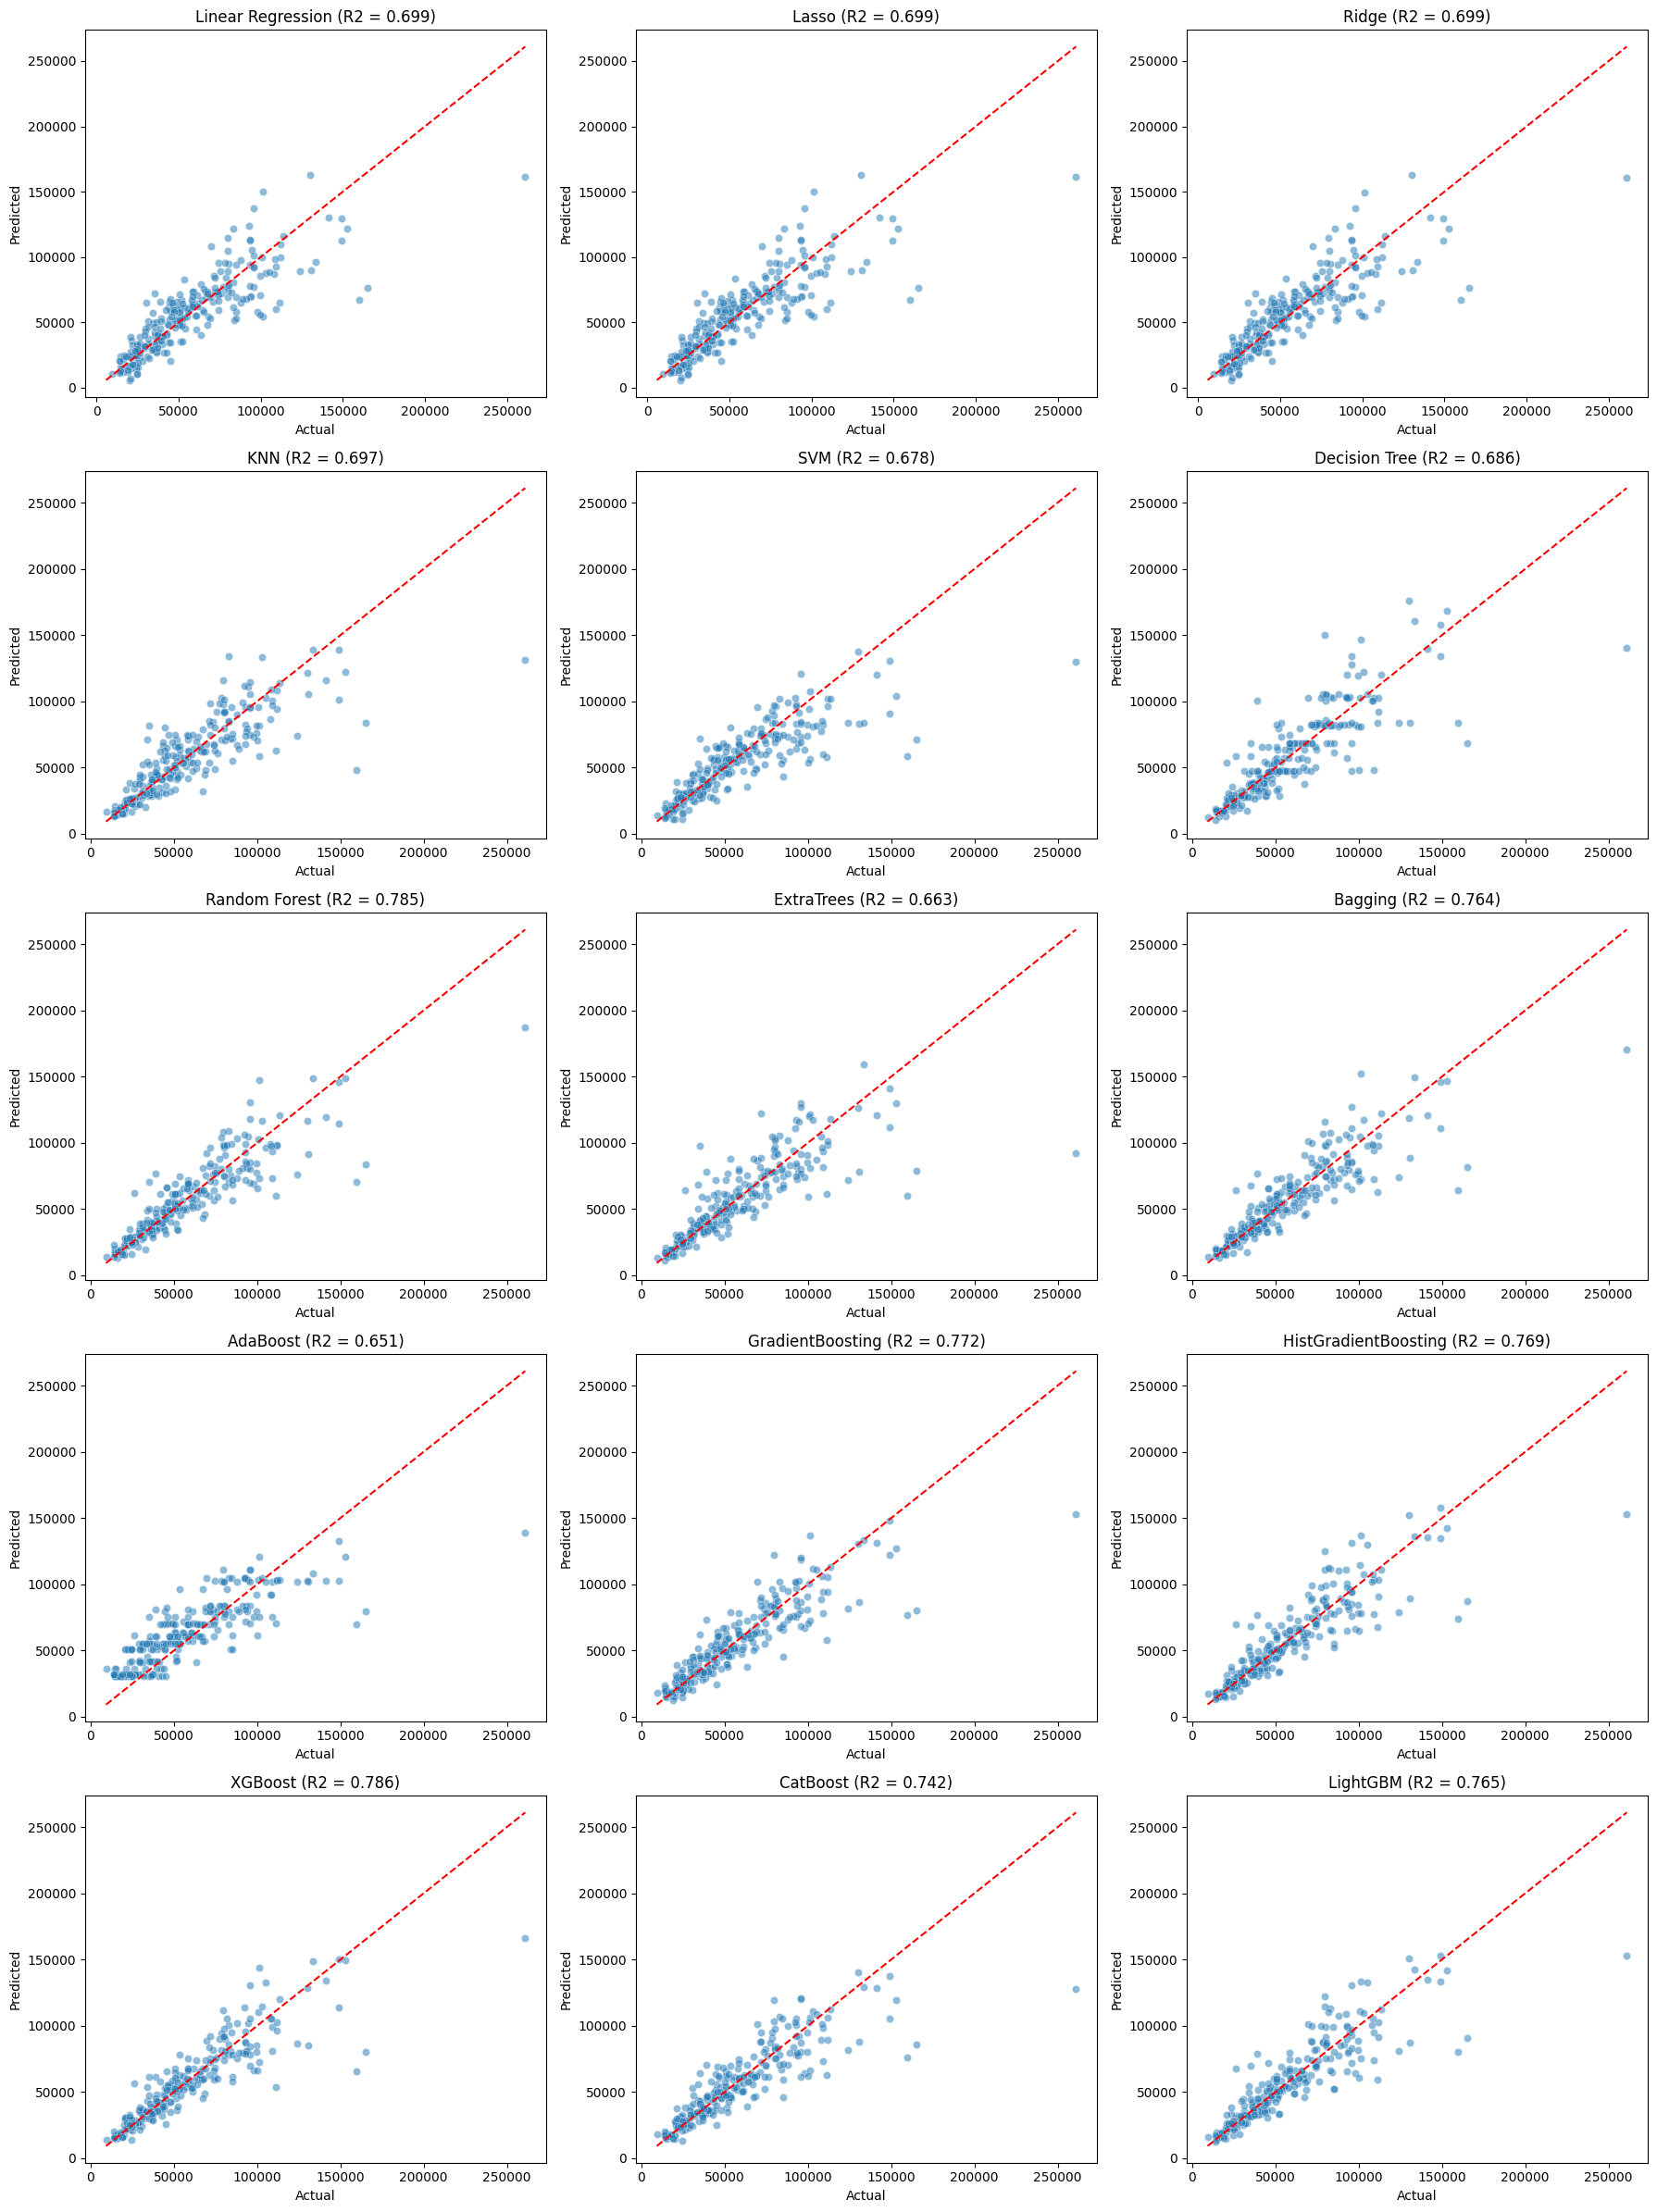

In [35]:
fig, axes = plt.subplots(5, 3, figsize=(18, 24))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(all_preds.items()):
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, ax=axes[i])
    low = min(np.min(y_test), np.min(y_pred))
    high = max(np.max(y_test), np.max(y_pred))
    axes[i].plot([low, high], [low, high], color='red', linestyle='--')
    axes[i].set_title(f"{name} (R2 = {r2_score(y_test, y_pred):.3f})")
    axes[i].set_xlabel('Actual')
    axes[i].set_ylabel('Predicted')

plt.tight_layout()
plt.show()

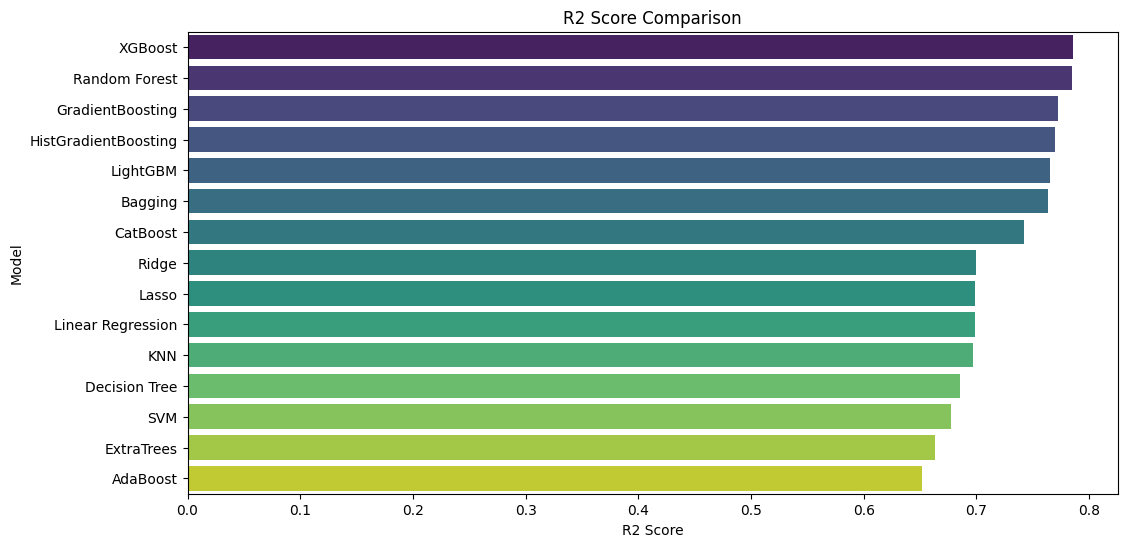

In [36]:
plt.figure(figsize=(12, 6))
sns.barplot(data=results_df, x='R2 Score', y='Model', hue='Model', palette='viridis', legend=False)
plt.title('R2 Score Comparison')
plt.show()

## Select the best model
We pick the best model using Cross Validation on the training set only (the test set is not touched).

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_score

cv_scores = {}
for name, m in models.items():
    cv_scores[name] = cross_val_score(clone(m), X_train_scaled, y_train, cv=3, scoring='r2', n_jobs=-1).mean()

cv_df = pd.DataFrame({'Model': list(cv_scores.keys()), 'CV R2': list(cv_scores.values())})
cv_df = cv_df.sort_values(by='CV R2', ascending=False).reset_index(drop=True)
cv_df

## GridSearchCV on the best model

In [ ]:
param_grids = {
    "Linear Regression": {},
    "Lasso": {"alpha": [0.01, 0.1, 1, 10]},
    "Ridge": {"alpha": [0.1, 1, 10, 100]},
    "KNN": {"n_neighbors": [3, 5, 7, 11], "weights": ["uniform", "distance"]},
    "SVM": {"C": [1, 10, 100]},
    "Decision Tree": {"max_depth": [5, 10, 15, None], "min_samples_split": [2, 10]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "ExtraTrees": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "Bagging": {"n_estimators": [15, 30, 50]},
    "AdaBoost": {"n_estimators": [50, 100], "learning_rate": [0.1, 1]},
    "GradientBoosting": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
    "HistGradientBoosting": {"max_iter": [100, 200], "learning_rate": [0.05, 0.1]},
    "XGBoost": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 6]},
    "CatBoost": {"iterations": [100, 300], "depth": [4, 6]},
    "LightGBM": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "num_leaves": [31, 63]},
}

best_name = cv_df.loc[0, 'Model']
print('Best model:', best_name)

grid = GridSearchCV(clone(models[best_name]), param_grids.get(best_name, {}), cv=3, scoring='r2', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('best_params_:', grid.best_params_)
print('best_score_ :', grid.best_score_)

best_model = grid.best_estimator_

## Before vs after tuning (test set)

In [ ]:
base_model = clone(models[best_name])
base_model.fit(X_train_scaled, y_train)

rows = []
for label, m in [('Before tuning', base_model), ('After tuning', best_model)]:
    p = m.predict(X_test_scaled)
    rows.append({'Version': label,
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'R2': r2_score(y_test, p)})
pd.DataFrame(rows)

## Final evaluation

In [ ]:
y_pred = best_model.predict(X_test_scaled)
residuals = np.array(y_test) - y_pred

print('MAE :', mean_absolute_error(y_test, y_pred))
print('MSE :', mean_squared_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2  :', r2_score(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.5)
low, high = min(np.min(y_test), np.min(y_pred)), max(np.max(y_test), np.max(y_pred))
axes[0].plot([low, high], [low, high], color='red', linestyle='--')
axes[0].set_title('Actual vs Predicted')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')

# Residuals
axes[1].scatter(y_pred, residuals, alpha=0.5)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residuals Plot')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Residual (Actual - Predicted)')

plt.tight_layout()
plt.show()

### Interpretation (generated automatically)

In [ ]:
# Plain-English summary, generated from the real results above
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
avg_actual = np.mean(np.abs(y_test))

print(f"Best model: {best_name} with {grid.best_params_}")
print(f"- R2 = {r2:.3f}: the model explains about {r2*100:.1f}% of the variation in the target.")
print(f"- MAE = {mae:,.2f}: on average the prediction is off by this amount ({mae/avg_actual*100:.1f}% of the average actual value).")
if rmse > 1.5 * mae:
    print(f"- RMSE ({rmse:,.2f}) is much bigger than MAE, so there are some large errors (outliers) the model misses.")
else:
    print(f"- RMSE ({rmse:,.2f}) is close to MAE, so the errors are fairly even with no big outliers.")
print(f"- Mean residual = {residuals.mean():,.2f}: close to 0 means the model does not systematically over- or under-predict.")
print(f"- Tuning changed R2 from {rows[0]['R2']:.3f} to {rows[1]['R2']:.3f}.")